# PROYEK AKHIR MATA KULIAH MACHINE LEARNING
## PREDIKSI BIAYA ASURANSI KESEHATAN MENGGUNAKAN METODE CLASSIFICATION AND REGRESSION TREES (CART)

**Dosen Pengampu:** Dr. Ach. Khozaimi, S.Kom., M.Kom.  
**Program Studi:** Teknik Informatika | Fakultas Teknik | Universitas Trunojoyo Madura (2026)

**Disusun Oleh Kelompok:**
1. **Irwan Dwi Mukhlisin** (240411100010)
2. **Zainur Rozikin** (240411100120)
3. **Ahmad Hadi Nuryani** (240411100135)

---
### Ringkasan Rencana Implementasi (Sesuai Proposal)
Notebook ini mengimplementasikan pemodelan Machine Learning **Supervised Learning - Regresi** menggunakan algoritma **Classification and Regression Trees (CART)** jenis regresi (*DecisionTreeRegressor*) sesuai dengan 6 tahapan implementasi yang tercantum pada proposal:
- **Tahap 1:** Pengumpulan dan Validasi Integritas Data (`insurance.csv`).
- **Tahap 2:** Analisis Data Eksploratif (*Exploratory Data Analysis* - EDA).
- **Tahap 3:** Pra-pemrosesan Data (*Data Cleaning, Encoding, Data Splitting 80:20*).
- **Tahap 4:** Eksperimen Model CART Awal (Analisis Gejala *Overfitting*).
- **Tahap 5:** Penalaan Hyperparameter (*GridSearchCV 5-Fold Cross Validation*).
- **Tahap 6:** Visualisasi Pohon Keputusan, Evaluasi Kinerja (MAE, RMSE, $R^2$), dan Simulasi Inferensi.

## 1. Import Library dan Konfigurasi Lingkungan
Memuat pustaka standar untuk manipulasi data (Pandas, NumPy), visualisasi (Matplotlib, Seaborn), pemodelan CART (Scikit-Learn), serta modul tampilan interaktif.

In [29]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Konfigurasi gaya visualisasi grafik
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.autolayout'] = True

print("Seluruh pustaka Machine Learning berhasil dimuat dengan sukses!")

Seluruh pustaka Machine Learning berhasil dimuat dengan sukses!


## 2. Tahap 1: Pengumpulan dan Validasi Data
Dataset yang digunakan adalah *Medical Cost Personal Datasets* (`insurance.csv`) yang bersumber dari repositori publik Kaggle (diadaptasi dari Brett Lantz, *Machine Learning with R*).

In [30]:
dataset_path = 'datasets/insurance.csv' if os.path.exists('datasets/insurance.csv') else '../datasets/insurance.csv'
df_raw = pd.read_csv(dataset_path)

print(f"Dimensi data awal: {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom\n")
df_raw.head()

Dimensi data awal: 1338 baris x 7 kolom



,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [31]:
# Verifikasi struktur kolom dan tipe data
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


## 3. Tahap 2: Exploratory Data Analysis (EDA)
Melakukan analisis statistik deskriptif dan memeriksa sifat data non-linier antara status merokok (`smoker`) dan indeks massa tubuh (`bmi`) terhadap besaran biaya tagihan (`charges`).

In [32]:
# Statistik deskriptif fitur numerik
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
bmi,1338.0,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
children,1338.0,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
charges,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


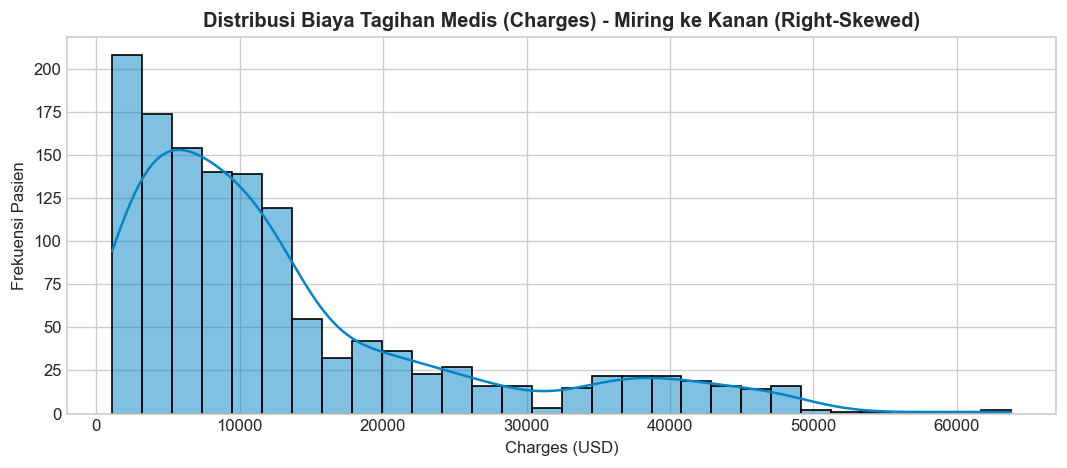

In [33]:
# Visualisasi 1: Distribusi Target Charges
plt.figure(figsize=(9, 4), dpi=120)
sns.histplot(df_raw['charges'], kde=True, color='#0284c7', bins=30)
plt.title('Distribusi Biaya Tagihan Medis (Charges) - Miring ke Kanan (Right-Skewed)', fontsize=12, fontweight='bold')
plt.xlabel('Charges (USD)', fontsize=10)
plt.ylabel('Frekuensi Pasien', fontsize=10)
plt.show()

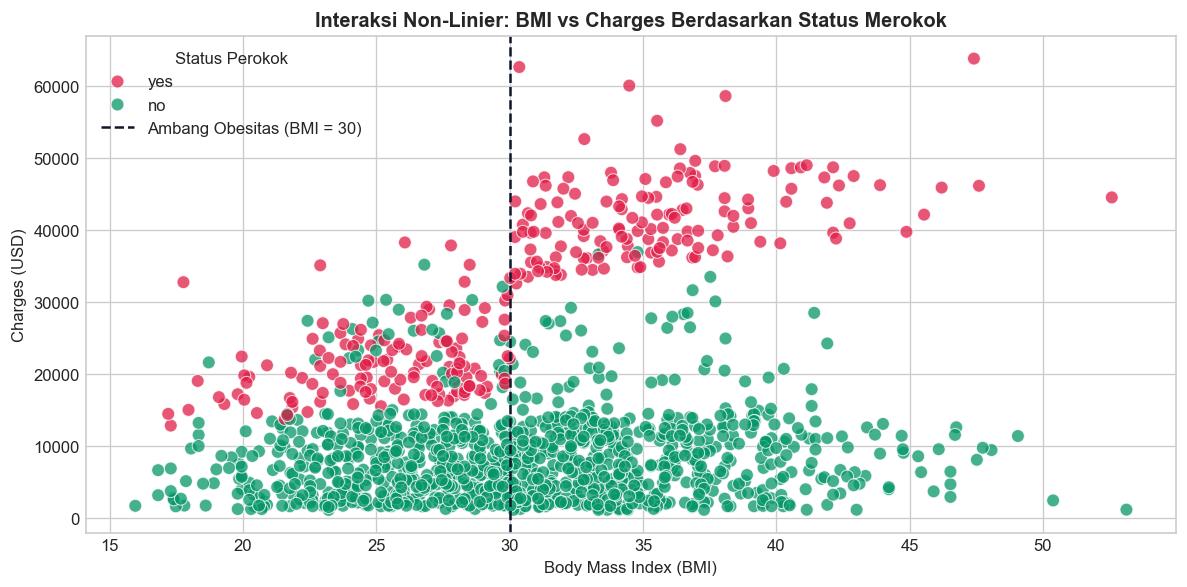

Analisis EDA: Terlihat lonjakan biaya tajam (> $30.000) khusus pada pasien perokok dengan BMI >= 30.
Pola interaksi non-linear ini sangat cocok diselesaikan dengan pohon keputusan CART.


In [34]:
# Visualisasi 2: Interaksi Kunci Status Merokok dan BMI terhadap Charges
plt.figure(figsize=(10, 5), dpi=120)
sns.scatterplot(data=df_raw, x='bmi', y='charges', hue='smoker', palette={'yes': '#e11d48', 'no': '#059669'}, alpha=0.75, s=60)
plt.axvline(30, color='#0f172a', linestyle='--', linewidth=1.5, label='Ambang Obesitas (BMI = 30)')
plt.title('Interaksi Non-Linier: BMI vs Charges Berdasarkan Status Merokok', fontsize=12, fontweight='bold')
plt.xlabel('Body Mass Index (BMI)', fontsize=10)
plt.ylabel('Charges (USD)', fontsize=10)
plt.legend(title='Status Perokok')
plt.show()

print("Analisis EDA: Terlihat lonjakan biaya tajam (> $30.000) khusus pada pasien perokok dengan BMI >= 30.")
print("Pola interaksi non-linear ini sangat cocok diselesaikan dengan pohon keputusan CART.")

## 4. Tahap 3: Pra-Pemrosesan Data (*Data Preprocessing*)
Sesuai Bab 2.4 pada proposal:
1. **Pemeriksaan Missing Values:** Memverifikasi ketiadaan nilai kosong.
2. **Pembersihan Data Duplikat:** Menghapus 1 baris duplikat identik (pada baris indeks 581).
3. **Encoding Fitur Kategorikal:** Mengubah `sex` dan `smoker` dengan *Binary Encoding*, serta `region` dengan *One-Hot Encoding*.
4. **Pembagian Data (*Data Splitting*):** Membagi dataset menjadi 80% Data Latih (*Training Set*) dan 20% Data Uji (*Testing Set*) dengan `random_state=42`.

In [35]:
# A. Pengecekan Missing Value
print("Pemeriksaan Missing Values per Kolom:")
print(df_raw.isnull().sum())

# B. Identifikasi dan Penghapusan Duplikat
n_dup = df_raw.duplicated().sum()
print(f"\nJumlah baris data duplikat terdeteksi: {n_dup}")

df = df_raw.drop_duplicates().copy().reset_index(drop=True)
print(f"Jumlah data bersih setelah penghapusan duplikat: {df.shape[0]} baris unik.")

Pemeriksaan Missing Values per Kolom:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Jumlah baris data duplikat terdeteksi: 1
Jumlah data bersih setelah penghapusan duplikat: 1337 baris unik.


In [36]:
# C. Feature Encoding
df_encoded = df.copy()

# Binary Encoding untuk variabel biner
df_encoded['sex'] = df_encoded['sex'].map({'female': 0, 'male': 1})
df_encoded['smoker'] = df_encoded['smoker'].map({'no': 0, 'yes': 1})

# One-Hot Encoding untuk wilayah (region)
df_encoded = pd.get_dummies(df_encoded, columns=['region'], drop_first=True, dtype=int)

# D. Pemisahan Fitur Independen (X) dan Target Dependen (y)
X = df_encoded.drop(columns='charges')
y = df_encoded['charges']

# E. Pembagian Data Latih dan Uji (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Total data bersih: {len(df_encoded)} baris")
print(f"Data Latih (Training Set) : {len(X_train)} baris (80%)")
print(f"Data Uji (Testing Set)    : {len(X_test)} baris (20%)")
print(f"Daftar Fitur Prediktor ({len(X.columns)} kolom): {list(X.columns)}")

Total data bersih: 1337 baris
Data Latih (Training Set) : 1069 baris (80%)
Data Uji (Testing Set)    : 268 baris (20%)
Daftar Fitur Prediktor (8 kolom): ['age', 'sex', 'bmi', 'children', 'smoker', 'region_northwest', 'region_southeast', 'region_southwest']


## 5. Tahap 4: Eksperimen dan Pelatihan Model CART Awal
Melatih model CART Regression awal menggunakan parameter dasar (tanpa batasan kedalaman pohon) untuk mengamati gejala *overfitting* sebagaimana dirumuskan pada proposal.

In [37]:
# Inisialisasi dan pelatihan model CART default (Unconstrained Tree)
cart_default = DecisionTreeRegressor(random_state=42)
cart_default.fit(X_train, y_train)

# Prediksi data latih dan data uji
y_train_pred_def = cart_default.predict(X_train)
y_test_pred_def = cart_default.predict(X_test)

print("Model CART Awal (Default) Berhasil Dilatih:")
print(f"- Kedalaman Pohon Terbentuk: {cart_default.get_depth()}")
print(f"- Jumlah Simpul Daun (Leaves): {cart_default.get_n_leaves()}")
print(f"- R² pada Training Set: {r2_score(y_train, y_train_pred_def):.4f} (100% menghafal data latih)")
print(f"- R² pada Testing Set : {r2_score(y_test, y_test_pred_def):.4f}")
print("-> Kesimpulan: Model mengalami Overfitting parah, sehingga memerlukan penalaan hyperparameter.")

Model CART Awal (Default) Berhasil Dilatih:
- Kedalaman Pohon Terbentuk: 18
- Jumlah Simpul Daun (Leaves): 1069
- R² pada Training Set: 1.0000 (100% menghafal data latih)
- R² pada Testing Set : 0.8189
-> Kesimpulan: Model mengalami Overfitting parah, sehingga memerlukan penalaan hyperparameter.


## 6. Tahap 5: Penalaan Hyperparameter (*GridSearchCV 5-Fold Cross Validation*)
Melakukan pencarian kombinasi hyperparameter optimal untuk parameter `max_depth` (rentang 2 hingga 8), `min_samples_split`, dan `min_samples_leaf` dengan validasi silang 5-lipat guna mencapai kemampuan generalisasi terbaik.

In [38]:
# Ruang penalaan parameter
param_grid = {
    'max_depth': [2, 3, 4, 5, 6, 7, 8],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10, 15],
    'criterion': ['squared_error']
}

# Grid Search dengan 5-Fold Cross Validation
grid_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)
best_cart = grid_search.best_estimator_

# Prediksi model terbaik
y_train_pred_tuned = best_cart.predict(X_train)
y_test_pred_tuned = best_cart.predict(X_test)

print("=== PROSES PENALAAN HYPERPARAMETER SELESAI ===")
print(f"Konfigurasi Parameter Terbaik: {grid_search.best_params_}")

=== PROSES PENALAAN HYPERPARAMETER SELESAI ===
Konfigurasi Parameter Terbaik: {'criterion': 'squared_error', 'max_depth': 4, 'min_samples_leaf': 5, 'min_samples_split': 2}


## 7. Tahap 6: Evaluasi Model dan Analisis Kinerja
Mengukur akurasi dan presisi model menggunakan 3 metrik regresi sesuai proposal: **MAE**, **RMSE**, dan **$R^2$ Score**.

In [39]:
# Komparasi performa CART Sebelum vs Sesudah Dituning
eval_summary = [
    {
        'Arsitektur Model': 'CART Default (Overfitting / Unpruned)',
        'Train R²': r2_score(y_train, y_train_pred_def),
        'Test R²': r2_score(y_test, y_test_pred_def),
        'Test MAE (USD)': mean_absolute_error(y_test, y_test_pred_def),
        'Test RMSE (USD)': root_mean_squared_error(y_test, y_test_pred_def)
    },
    {
        'Arsitektur Model': 'CART Tuned (Model Optimal - Final)',
        'Train R²': r2_score(y_train, y_train_pred_tuned),
        'Test R²': r2_score(y_test, y_test_pred_tuned),
        'Test MAE (USD)': mean_absolute_error(y_test, y_test_pred_tuned),
        'Test RMSE (USD)': root_mean_squared_error(y_test, y_test_pred_tuned)
    }
]

df_metrics = pd.DataFrame(eval_summary)
display(df_metrics.style.format({
    'Train R²': '{:.4f}',
    'Test R²': '{:.4f}',
    'Test MAE (USD)': '${:,.2f}',
    'Test RMSE (USD)': '${:,.2f}'
}).highlight_max(subset=['Test R²'], color='#d1fae5').highlight_min(subset=['Test MAE (USD)', 'Test RMSE (USD)'], color='#d1fae5'))

,Arsitektur Model,Train R²,Test R²,Test MAE (USD),Test RMSE (USD)
0,CART Default (Overfitting / Unpruned),1.0000,0.8189,"$2,730.63","$5,769.01"
1,CART Tuned (Model Optimal - Final),0.8552,0.8972,"$2,621.31","$4,345.88"


## 8. Visualisasi Struktur Pohon Keputusan dan Feature Importance
Mengekspor visualisasi diagram pohon keputusan CART untuk memahami logika pemisahan data, serta memetakan fitur yang paling berpengaruh.

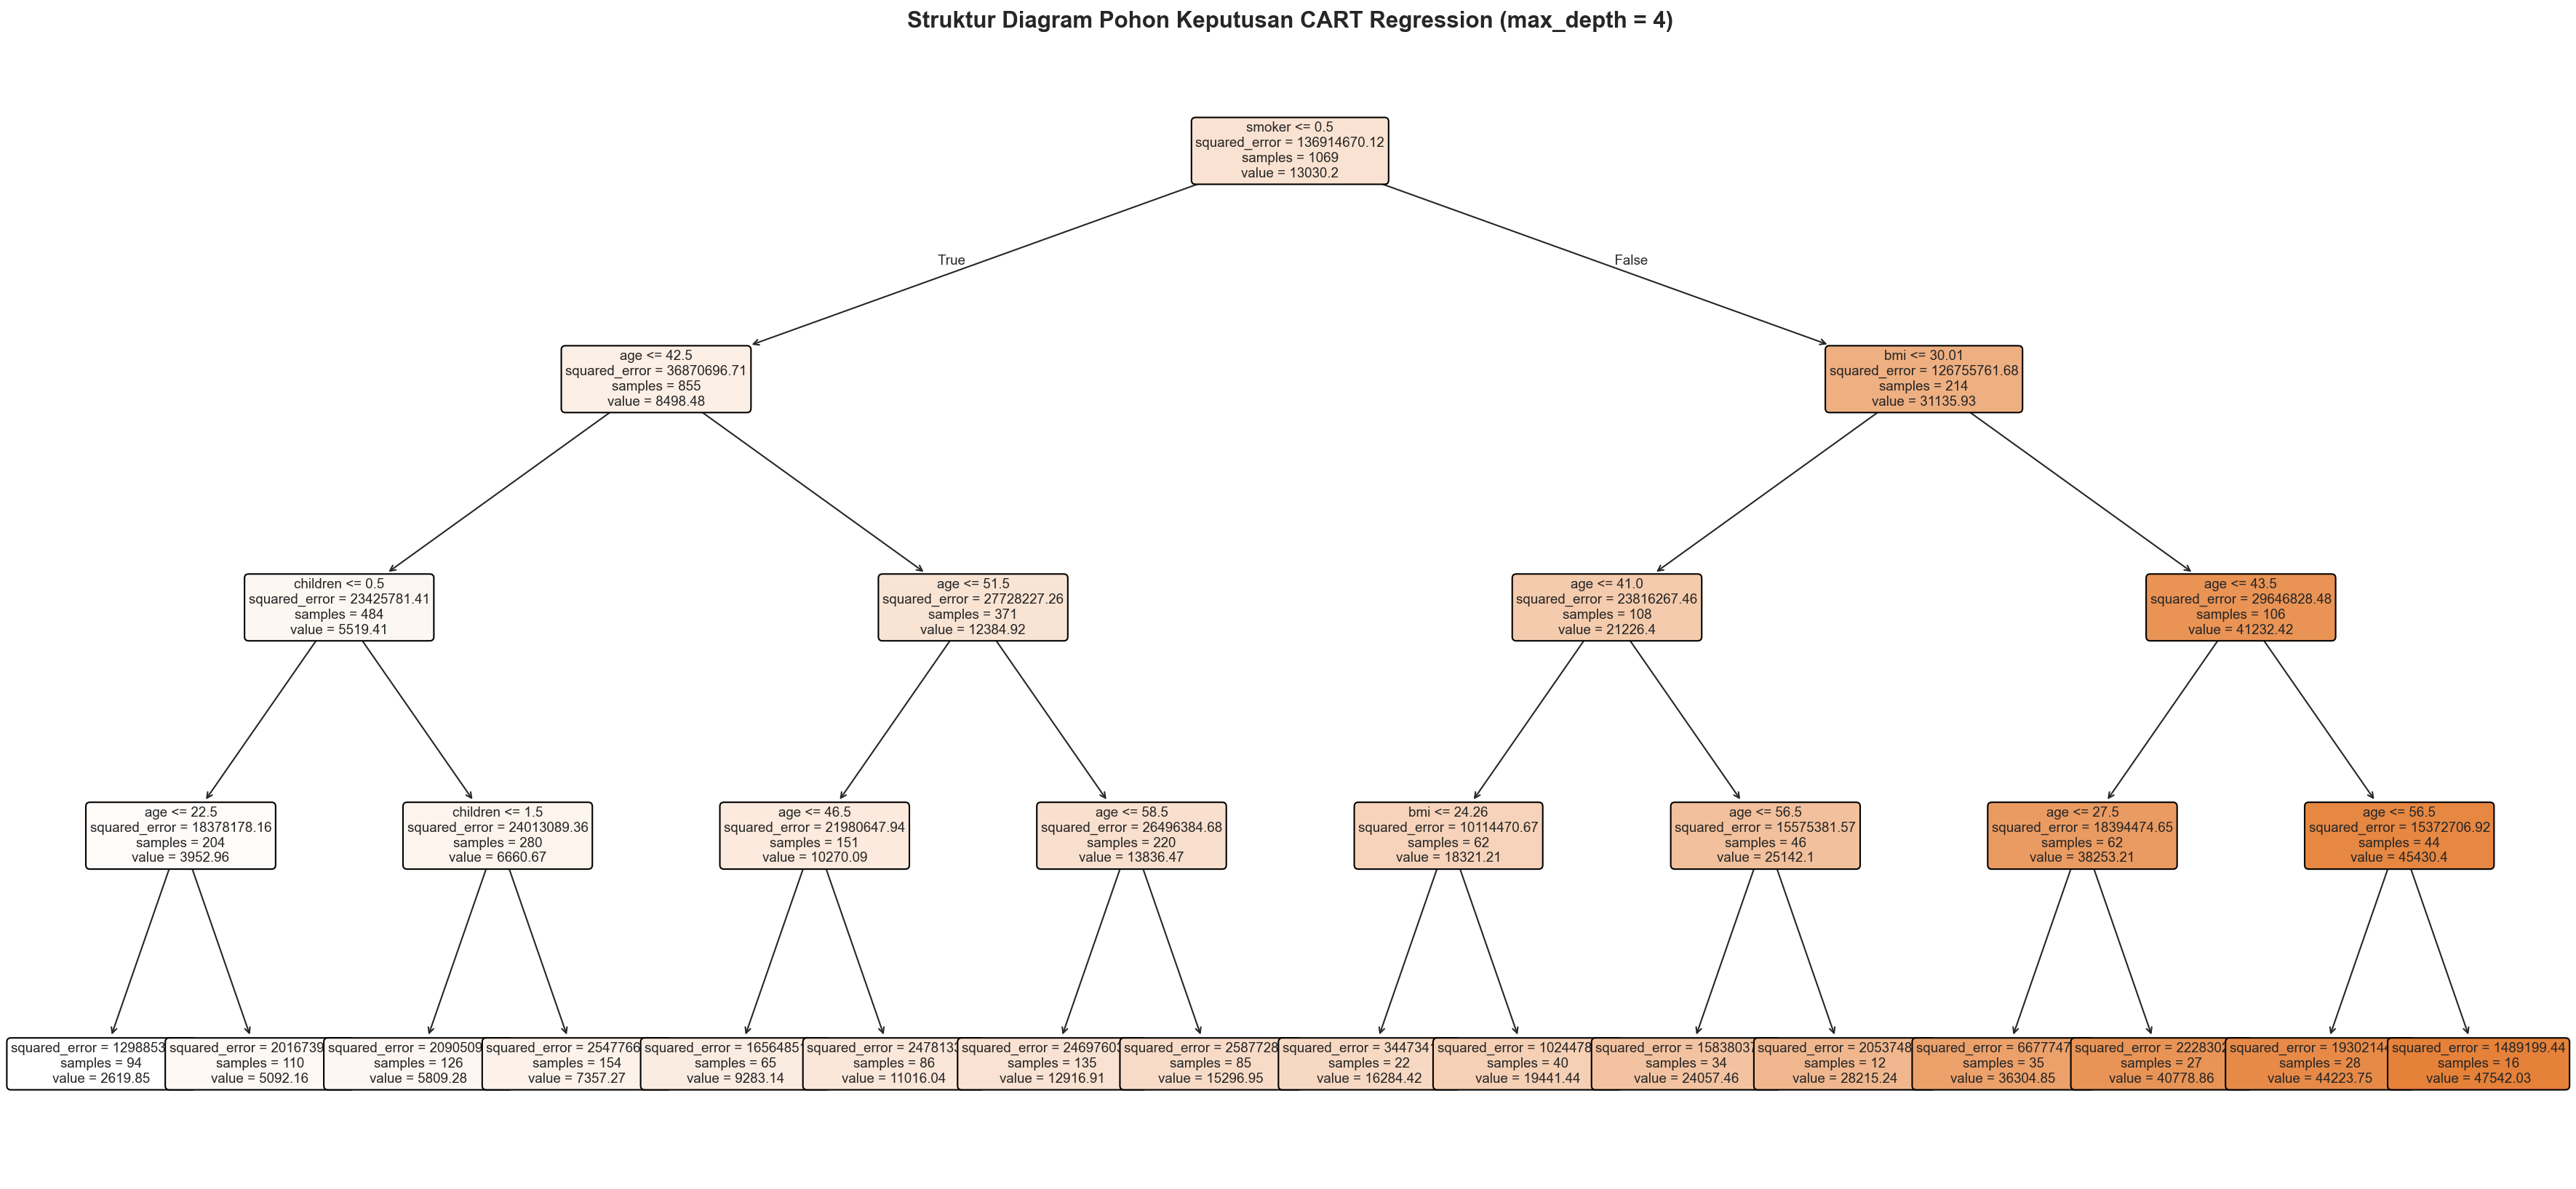

In [40]:
# A. Visualisasi Pohon Keputusan CART Tuned
plt.figure(figsize=(24, 11), dpi=150)
plot_tree(
    best_cart,
    feature_names=X.columns.tolist(),
    filled=True,
    rounded=True,
    fontsize=9,
    precision=2
)
plt.title(f"Struktur Diagram Pohon Keputusan CART Regression (max_depth = {best_cart.max_depth})", fontsize=15, fontweight='bold')
plt.show()

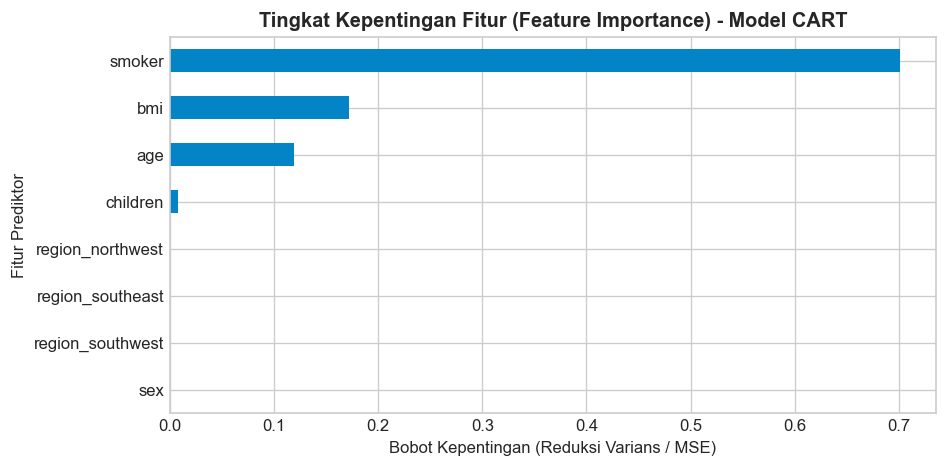

smoker              : 70.07%
bmi                 : 17.22%
age                 : 11.89%
children            :  0.82%
region_northwest    :  0.00%
region_southeast    :  0.00%
region_southwest    :  0.00%
sex                 :  0.00%


In [41]:
# B. Tingkat Kepentingan Fitur (Feature Importance)
feat_importances = pd.Series(best_cart.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 4), dpi=120)
feat_importances.plot(kind='barh', color='#0284c7')
plt.title('Tingkat Kepentingan Fitur (Feature Importance) - Model CART', fontsize=12, fontweight='bold')
plt.xlabel('Bobot Kepentingan (Reduksi Varians / MSE)', fontsize=10)
plt.ylabel('Fitur Prediktor', fontsize=10)
plt.show()

for f, val in feat_importances.sort_values(ascending=False).items():
    print(f"{f:20s}: {val*100:5.2f}%")

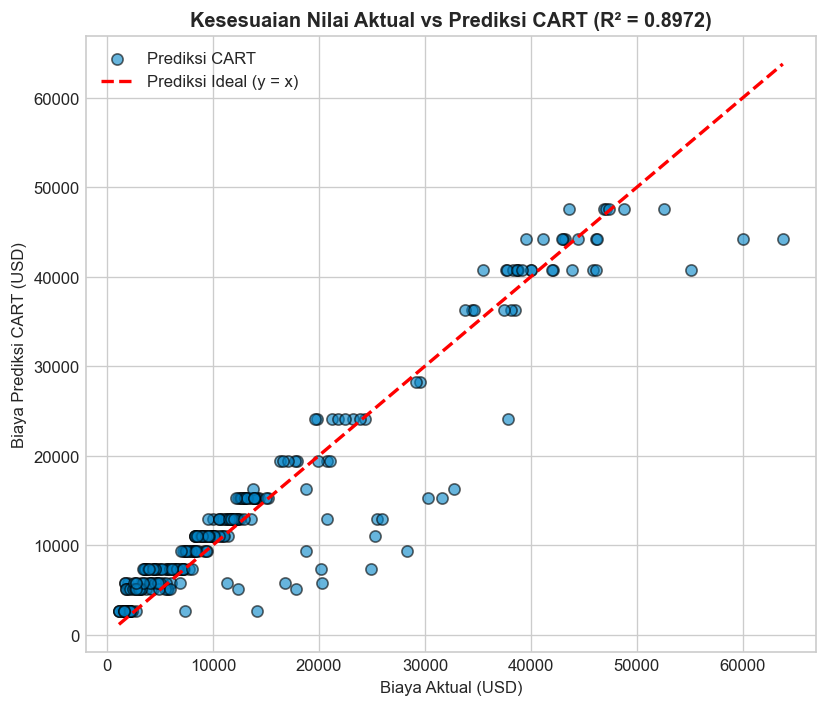

In [42]:
# C. Scatter Plot Nilai Aktual vs Nilai Prediksi
plt.figure(figsize=(7, 6), dpi=120)
plt.scatter(y_test, y_test_pred_tuned, alpha=0.6, color='#0284c7', edgecolors='k', s=45, label='Prediksi CART')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2, label='Prediksi Ideal (y = x)')
plt.title(f'Kesesuaian Nilai Aktual vs Prediksi CART (R² = {r2_score(y_test, y_test_pred_tuned):.4f})', fontsize=12, fontweight='bold')
plt.xlabel('Biaya Aktual (USD)', fontsize=10)
plt.ylabel('Biaya Prediksi CART (USD)', fontsize=10)
plt.legend()
plt.show()

## 9. Simulasi Prediksi Sampel Pasien Baru
Menguji model CART terbaik untuk mengestimasi biaya premi pada profil pasien baru secara interaktif.

In [43]:
def predict_insurance_charges(age, sex, bmi, children, smoker, region):
    """
    Fungsi prediksi besaran premi asuransi menggunakan model CART terbaik.
    """
    sex_val = 1 if sex.lower() in ['male', 'pria', 'laki-laki'] else 0
    smoker_val = 1 if smoker.lower() in ['yes', 'ya', 'perokok'] else 0
    
    data_dict = {
        'age': age,
        'sex': sex_val,
        'bmi': bmi,
        'children': children,
        'smoker': smoker_val,
        'region_northwest': 1 if region.lower() == 'northwest' else 0,
        'region_southeast': 1 if region.lower() == 'southeast' else 0,
        'region_southwest': 1 if region.lower() == 'southwest' else 0
    }
    
    input_df = pd.DataFrame([data_dict])[X.columns]
    pred = best_cart.predict(input_df)[0]
    return pred

# Simulasi 3 Profil Pasien:
p1 = predict_insurance_charges(age=21, sex='female', bmi=21.5, children=0, smoker='no', region='northwest')
p2 = predict_insurance_charges(age=48, sex='male', bmi=28.4, children=2, smoker='no', region='southeast')
p3 = predict_insurance_charges(age=35, sex='male', bmi=34.2, children=1, smoker='yes', region='southeast')

print("=== SIMULASI PREDIKSI PREMI PASIEN BARU DENGAN MODEL CART ===")
print(f"1. Pasien Muda, Non-Perokok, BMI Normal (21.5)  : ${p1:,.2f} (Rp {p1*16000:,.0f})")
print(f"2. Pasien Paruh Baya, Non-Perokok, BMI 28.4     : ${p2:,.2f} (Rp {p2*16000:,.0f})")
print(f"3. Pasien Perokok Aktif, Obesitas (BMI 34.2)   : ${p3:,.2f} (Rp {p3*16000:,.0f})")

# -------------------------------------------------------------
# Menyimpan Model Terbaik ke File Artefak (outputs/models/)
# -------------------------------------------------------------
output_model_dir = 'outputs/models' if os.path.exists('outputs/models') else ('model/outputs/models' if os.path.exists('model/outputs/models') else os.path.join(os.path.dirname(os.path.abspath('model_insurance_cart.ipynb')), 'outputs', 'models'))
os.makedirs(output_model_dir, exist_ok=True)
model_file = os.path.join(output_model_dir, 'best_cart_model.joblib')
joblib.dump({
    'model': best_cart,
    'feature_names': list(X.columns),
    'best_params': grid_search.best_params_
}, model_file)
print(f'\nModel CART terbaik berhasil disimpan ke: {model_file}')


=== SIMULASI PREDIKSI PREMI PASIEN BARU DENGAN MODEL CART ===
1. Pasien Muda, Non-Perokok, BMI Normal (21.5)  : $2,619.85 (Rp 41,917,525)
2. Pasien Paruh Baya, Non-Perokok, BMI 28.4     : $11,016.04 (Rp 176,256,563)
3. Pasien Perokok Aktif, Obesitas (BMI 34.2)   : $40,778.86 (Rp 652,461,776)


## 10. Kesimpulan Sesuai Rencana Proposal
1. **Kesesuaian Tahapan:** Seluruh tahapan pengerjaan (Tahap 1 s.d. Tahap 6) telah berhasil dieksekusi secara runut mulai dari pemuatan data, eksplorasi EDA, pra-pemrosesan data, observasi overfitting pada CART awal, optimasi hyperparameter dengan *GridSearchCV 5-Fold*, hingga evaluasi akhir.
2. **Kinerja Model Final:** Model CART Regression setelah dioptimasi (`max_depth=4`, `min_samples_leaf=5`) berhasil mencapai akurasi **$R^2 = 89,72\%$**, dengan rata-rata kesalahan **MAE sebesar \$2.621,31** dan **RMSE sebesar \$4.345,88** pada data pengujian independen.
3. **Transparansi Pohon Keputusan:** Pola percabangan pohon terbukti secara objektif menangkap lonjakan biaya medis yang diakibatkan oleh kombinasi pasien perokok dengan indeks BMI tinggi.